In [24]:
import pandas as pd
import numpy as np

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

## Load Training and Testing Datasets

In [25]:
# Load training and testing datasets
X_train = pd.read_csv("../dataset/processed/X_train.csv")
X_test = pd.read_csv("../dataset/processed/X_test.csv")

y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze("columns")

# Verify dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (36168, 16)
Testing features: (9043, 16)
Training target: (36168,)
Testing target: (9043,)


## Define preprocessing pipelines

In [26]:
# Identify numerical and categorical features
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Numerical preprocessing for Logistic Regression
numerical_pipeline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for tree-based models
numerical_pipeline_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Logistic Regression preprocessor
preprocessor_lr = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_lr, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Random Forest preprocessor
preprocessor_rf = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_tree, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Gradient Boosting preprocessor
preprocessor_gb = ColumnTransformer(transformers=[
    ("num", numerical_pipeline_tree, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [27]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [28]:
# Train Logistic Regression
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [29]:
# Predict target classes
y_pred_lr = lr_model.predict(X_test)

# Predict subscription probabilities
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

In [30]:
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

# Display evaluation results
print("Logistic Regression - Baseline Performance")
print("-------------------------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-Score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

Logistic Regression - Baseline Performance
-------------------------------------------
Accuracy:  0.8935
Precision: 0.6678
Recall:    0.1786
F1-Score:  0.2819
ROC-AUC:   0.7717


In [31]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Subscription", "Subscription"]
))

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.67      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



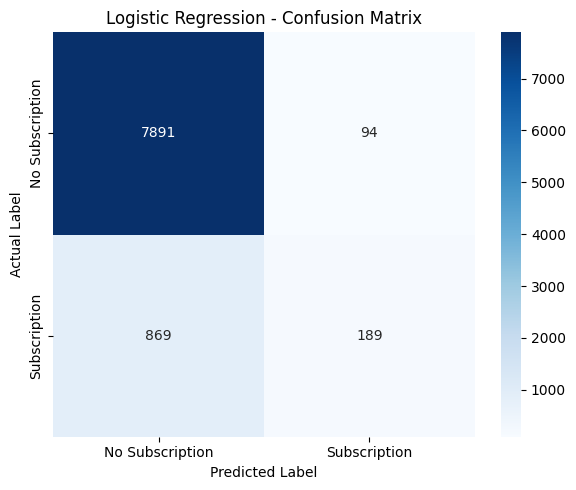

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Visualise confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Subscription", "Subscription"],
    yticklabels=["No Subscription", "Subscription"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()